<center><h1>Chen_Jessica_HW7</h1></center>

Name: Jessica Chen
<br>
Github Username: jc6006 
<br>
USC ID: 9760667304

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [60]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, accuracy_score
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

### (a) Download the Anuran Calls (MFCCs) Data Set

In [61]:
df=pd.read_csv("..\data\MFCCs\Frogs_MFCCs.csv")
feat=[c for c in df.columns if c.startswith("MFCCs")]
labels=["Family","Genus","Species"]
x=df[feat].values
y=df[labels].values
xtr,xte,ytr,yte=train_test_split(x,y,train_size=0.7,random_state=0)
scaler=StandardScaler().fit(xtr)
xtr_s,xte_s=scaler.transform(xtr),scaler.transform(xte)

### (b) Train a classifier for each label

#### (i) Research

Exact Match Ratio: proportion of samples where the entire set of predicted labels matches the true set of labels <br>
Hamming Score: proportion of correctly predicted labels for each sample, averaged across all samples <br>
Hamming Loss: proportion of the total labels across all samples that are incorrectly predicted

#### (ii) Train a SVM for each of the labels

In [62]:
def ml_mets(ytrue,ypred):
    mism=(ytrue!=ypred)
    exact=np.mean(~mism.any(axis=1))
    h_loss=mism.mean()
    return dict(ExactMatch=exact,HammingScore=1-h_loss,HammingLoss=h_loss,AvgHammingDist=mism.sum(1).mean(),**{f"Acc_{l}": 1-mism[:,j].mean() for j,l in enumerate(labels)})
def run_BV(make_model,grids,xtr_,xte_,name):
    preds,best=[],{}
    for j,l in enumerate(labels):
        gs=GridSearchCV(make_model(),grids,cv=10,n_jobs=-1,scoring="accuracy")
        gs.fit(xtr_,ytr[:,j])
        best[l]=(gs.best_params_,round(gs.best_score_,4))
        preds.append(gs.predict(xte_))
    yp=np.column_stack(preds)
    m=ml_mets(yte,yp)
    print(name)
    rows=[]
    for l in labels:
        p={k.split("__")[-1]: v for k,v in best[l][0].items()}
        if "gamma" in p: p["sigma"]=1/np.sqrt(2*p["gamma"])
        rows.append({"Label": l, **p, "CV acc": best[l][1]})
    display(pd.DataFrame(rows).set_index("Label"))
    display(pd.DataFrame([{k:round(v,4) for k,v in m.items()}], index=["test"]).T)
    return m,best
def gauss_model():
    return OneVsRestClassifier(SVC(kernel="rbf"))
grid_std={"estimator__C":[1,10,100],"estimator__gamma":[0.01,0.05]}
res={}
res["Gaussian SVM (standardized)"], _=run_BV(gauss_model,grid_std,xtr_s,xte_s,"Gaussian SVM (standardized)")

Gaussian SVM (standardized)


,C,gamma,sigma,CV acc
Label,,,,
Family,10,0.05,3.162278,0.9927
Genus,100,0.01,7.071068,0.9891
Species,100,0.01,7.071068,0.9883


,test
ExactMatch,0.9866
HammingScore,0.9910
HammingLoss,0.0090
AvgHammingDist,0.0269
Acc_Family,0.9944
Acc_Genus,0.9898
Acc_Species,0.9889


#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [63]:
def l1_model():return LinearSVC(penalty="l1",dual=False,tol=1e-3,max_iter=1000,random_state=0)
grid_l1={"C": [0.01,0.1,1]}
res["L1 linear SVM"], _=run_BV(l1_model,grid_l1,xtr_s,xte_s,"L1 linear SVM")

L1 linear SVM


,C,CV acc
Label,,
Family,1,0.9377
Genus,1,0.9525
Species,1,0.9587


,test
ExactMatch,0.9138
HammingScore,0.9458
HammingLoss,0.0542
AvgHammingDist,0.1626
Acc_Family,0.9338
Acc_Genus,0.9467
Acc_Species,0.9569


#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [64]:
def l1_smote_model():return ImbPipeline([("smote",SMOTE(random_state=0,k_neighbors=5)),("svm",LinearSVC(penalty="l1",dual=False,tol=1e-3,max_iter=1000,random_state=0))])
grid_sm={"svm__C":[0.01,0.1,1]}
res["L1 linear SVM + SMOTE"],_=run_BV(l1_smote_model,grid_sm,xtr_s,xte_s,"L1 linear SVM + SMOTE")
summary = pd.DataFrame(res).T
display(summary)

L1 linear SVM + SMOTE


,C,CV acc
Label,,
Family,1.0,0.9216
Genus,1.0,0.9196
Species,0.1,0.9597


,test
ExactMatch,0.8555
HammingScore,0.9230
HammingLoss,0.0770
AvgHammingDist,0.2311
Acc_Family,0.9120
Acc_Genus,0.9037
Acc_Species,0.9532


,ExactMatch,HammingScore,HammingLoss,AvgHammingDist,Acc_Family,Acc_Genus,Acc_Species
Gaussian SVM (standardized),0.986568,0.991045,0.008955,0.026864,0.994442,0.989810,0.988884
L1 linear SVM,0.913849,0.945808,0.054192,0.162575,0.933766,0.946735,0.956925
L1 linear SVM + SMOTE,0.855489,0.922958,0.077042,0.231126,0.911996,0.903659,0.953219


## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

In [65]:
def choose_k(seed):
    scores={}
    for k in range(2,51):
        km=KMeans(n_clusters=k,n_init=1,random_state=seed).fit(x)
        scores[k]=silhouette_score(x,km.labels_,sample_size=1000,random_state=seed)
    k_best = max(scores,key=scores.get)
    return k_best,scores
k0,s0=choose_k(0)
print("Best k:",k0)

Best k: 4


### (b) Determine which family is the majority

In [66]:
def find_majority(cluster_ids):
    maj={}
    for c in np.unique(cluster_ids):
        idx = cluster_ids == c
        maj[c]=tuple(pd.Series(y[idx, j]).mode().iloc[0] for j in range(3))
    return maj
km0=KMeans(n_clusters=k0,n_init=3,random_state=0).fit(x)
maj0=find_majority(km0.labels_)
tab=pd.DataFrame([(c,(km0.labels_==c).sum(),*maj0[c]) for c in sorted(maj0)],columns=["cluster","size","Family","Genus","Species"])
print("k =",k0)
display(tab)

k = 4


,cluster,size,Family,Genus,Species
0,0,3584,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,1,2216,Hylidae,Hypsiboas,HypsiboasCordobae
2,2,663,Hylidae,Hypsiboas,HypsiboasCinerascens
3,3,732,Leptodactylidae,Adenomera,AdenomeraAndre


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [67]:
rows,ks = [],[]
for r in range(50):
    k,_=(k0, None) if r == 0 else choose_k(r)
    km=KMeans(n_clusters=k,n_init=3,random_state=r).fit(x)
    maj=find_majority(km.labels_)
    ypred=np.array([maj[c] for c in km.labels_])
    mism=(ypred!=y)
    dist=mism.sum(1).mean()
    rows.append(dict(k=k,HammingDistance=dist,HammingLoss=mism.mean(),HammingScore=1-mism.mean()))
mc=pd.DataFrame(rows)
print("chosen k:",mc.k.value_counts().sort_index().to_dict())
out = mc[["HammingDistance","HammingScore","HammingLoss"]].agg(["mean","std"])
display(out)

chosen k over 50 runs: {2: 6, 3: 14, 4: 22, 5: 1, 6: 7}


,HammingDistance,HammingScore,HammingLoss
mean,0.731942,0.756019,0.243981
std,0.132293,0.044098,0.044098


## 3. ISLR 12.6.2

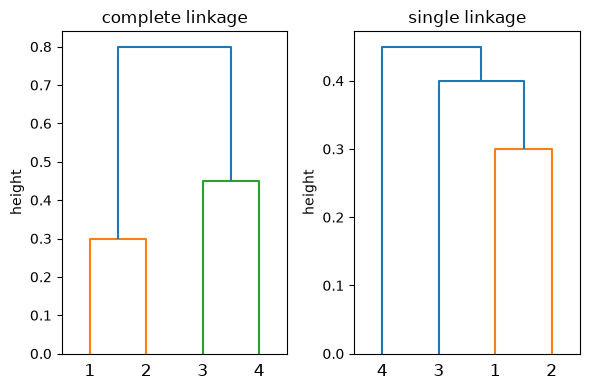

In [68]:
d=np.array([[0,.3,.4,.7],[.3,0,.5,.8],[.4,.5,0,.45],[.7,.8,.45,0]])
fig,ax=plt.subplots(1,2,figsize=(6,4))
for a,m in zip(ax,["complete","single"]):
    dendrogram(linkage(squareform(d),method=m),labels=[1,2,3,4],ax=a)
    a.set_title(f"{m} linkage")
    a.set_ylabel("height")
plt.tight_layout()
plt.show()

#### a)
(1,2): 0.3. <br>
{1,2} to 3: max(0.4, 0.5)=0.5 <br>
{1,2} to 4: max(0.7, 0.8)=0.8 <br>
3 to 4: 0.45 <br>
{1,2} and {3,4}: max(0.4, 0.7, 0.5, 0.8)=0.8 <br>

#### b)
(1,2): 0.3. <br>
{1,2} to 3: min(0.4, 0.5)=0.4 <br>
{1,2} to 4: min(0.7, 0.8)=0.7 <br>
3 to 4: 0.45 <br>
{1,2,3} and {4}: min(0.7, 0.8, 0.45)0.45 <br>

#### c)
{1,2} {3,4} <br>

#### d)
{1,2,3} {4} <br>

#### e)
Same as the first plot but with 1 & 2 leaves swapped.